### **Session 9 · Notebook 6 (extra) — Sutskever, tuned**

Session 9 deck, *Working with RNN (II): machine translation*. Run in Colab with a GPU (Runtime → Change runtime type → T4 GPU).

Notebook 5 overfitted: 21 M weights for 50,000 sentence pairs, train accuracy 82% against 59% on
validation, and a BLEU (20.5) below the simpler GRU of Notebook 2 (22.9). This notebook keeps the same
architecture idea (deep LSTM, reversed source) and adds the usual fixes, one switch per idea:

| # | Tweak | Why | Switch |
|---|---|---|---|
| 1 | **all** the ≤10-word pairs (~100,000 for training) | depth needs data | `USE_ALL_PAIRS` |
| 2 | dropout 0.3 + dropout on embeddings and before the output | less overfitting | `DROPOUT`, `EMB_DROPOUT` |
| 3 | label smoothing 0.1 | less over-confident (Session 6) | `LABEL_SMOOTHING` |
| 4 | *optional* **weight tying**: the output layer reuses the Spanish embedding | −4 M weights | `TIE_WEIGHTS` (off by default) |
| 5 | Spanish vocabulary 10,000 (was 15,000) | rare words are never learnt | `VOCAB` |
| 6 | `ReduceLROnPlateau` + patience 4 | fine steps at the end | `callbacks` |
| 7 | mixed precision, batch 128 | ~2× faster on a T4 (Session 6) | `MIXED`, `BATCH` |
| 8 | beam search k=8 with a length penalty, on **all** 5,000 test sentences | better decoding | `BEAM_K`, `ALPHA` |
| 9 | optional ensemble of several models | +1–3 BLEU, ×N time | `N_MODELS` |

**Same validation and test sentences as Notebooks 1–5**, so the BLEU is directly comparable.
Expected time on a T4 with `N_MODELS = 1`: about 25–35 minutes (training + beam search).

In [1]:
import os
os.environ.setdefault("KERAS_BACKEND", "tensorflow")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")      # hide TensorFlow info messages
import json, time, re, math, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers, ops
print("Keras", keras.__version__, "| TensorFlow", tf.__version__,
      "| GPU:", tf.config.list_physical_devices("GPU"))
keras.utils.set_random_seed(42)
os.makedirs("results", exist_ok=True)

I0000 00:00:1792219175.017971   11755 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792219176.387950   11755 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Keras 3.12.3 | TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 0. Parameters

In [2]:
DATA_DIR = "data"          # pairs.tsv AND spa.txt, both saved by Notebook 1
QUICK = False              # True: a short trial run (few batches, 2 epochs) to check that the code works

# ---- the tweaks (set any of them back to the Notebook 5 value to measure its effect) ----
USE_ALL_PAIRS = True       # NB5: False (50,000 training pairs)
VOCAB = 10000              # NB5: 15000
EMB, UNITS, LAYERS = 256, 512, 2
DROPOUT = 0.3              # NB5: 0.2 (inside the LSTMs)
EMB_DROPOUT = 0.3          # NB5: 0   (after the embeddings and before the output layer)
LABEL_SMOOTHING = 0.1      # NB5: 0
TIE_WEIGHTS = False        # True: share the Spanish embedding with the output layer (try it, see the note)
REVERSE = True             # Sutskever's trick (keep it)
MIXED = True               # mixed precision, only used if there is a GPU
BATCH = 128                # NB5: 64 (if the GPU runs out of memory: 64)
EPOCHS = 30                # maximum; EarlyStopping stops earlier
PATIENCE = 4               # NB5: 3
N_MODELS = 1               # ensemble size: 1 = a single model; 3 = three seeds (3x the time)
BEAM_K, ALPHA = 8, 0.7     # beam width and length-penalty exponent

SRC_LEN, TGT_LEN, MAX_WORDS = 12, 13, 10
if MIXED and tf.config.list_physical_devices("GPU"):
    keras.mixed_precision.set_global_policy("mixed_float16")
print("policy:", keras.mixed_precision.global_policy().name)

policy: mixed_float16


**Colab tip.** Every Colab notebook runs on its own machine, so a file saved by Notebook 1 is not
visible from Notebook 2. To share the data, mount your Google Drive in every notebook and point
`DATA_DIR` to the same Drive folder:

```python
from google.colab import drive
drive.mount("/content/drive")
DATA_DIR = "/content/drive/MyDrive/DL26/session9/data"
```
(Or simply upload `data/pairs.tsv`, created by Notebook 1, to the `data/` folder of this notebook.)

## 1. The data: the same validation and test sets, a larger training set
Notebook 1 kept 60,000 of the 108,409 pairs with at most 10 words. Here we read `spa.txt` again, apply the
same cleaning, and use **every other pair for training**. Any pair whose English sentence appears in the
validation or test set is removed from training, so nothing leaks.

In [3]:
pairs = pd.read_csv(os.path.join(DATA_DIR, "pairs.tsv"), sep="\t", keep_default_na=False)
val  = pairs[pairs.split == "val"].reset_index(drop=True)
test = pairs[pairs.split == "test"].reset_index(drop=True)
train = pairs[pairs.split == "train"].reset_index(drop=True)

def clean(text):                                  # exactly the cleaning of Notebook 1
    text = text.lower().replace("’", "'")
    text = re.sub(r"[^\w\s']", " ", text)
    text = text.replace("'", "")
    return " ".join(text.split())

if USE_ALL_PAIRS:
    raw = os.path.join(DATA_DIR, "spa.txt")
    if not os.path.exists(raw):
        raise FileNotFoundError(f"{raw} not found: Notebook 1 saves it next to pairs.tsv")
    with open(raw, encoding="utf-8") as f:
        lines = f.read().strip().split("\n")
    allp = pd.DataFrame({"en": [clean(l.split("\t")[0]) for l in lines],
                         "es": [clean(l.split("\t")[1]) for l in lines]})
    allp = allp[(allp.en.str.split().str.len() <= MAX_WORDS) & (allp.es.str.split().str.len() <= MAX_WORDS)
                & (allp.en != "") & (allp.es != "")]
    held_out = set(val.en) | set(test.en)                       # no leakage into val / test
    train = allp[~allp.en.isin(held_out)].drop_duplicates().sample(frac=1.0, random_state=42)
    train = train.reset_index(drop=True)
print(f"train {len(train):,} | val {len(val):,} | test {len(test):,} pairs")

train 94,952 | val 5,000 | test 5,000 pairs


## 2. Reversed source, vocabularies and teacher forcing

In [4]:
def prepare_source(sentence):
    return " ".join(sentence.split()[::-1]) if REVERSE else sentence

print(prepare_source("i am hungry"))

hungry am i


In [5]:
# Text -> integers. The text is already clean (lower case, no punctuation), so we only split on spaces.
# Index 0 is padding, index 1 is [UNK] (unknown word).
src_vec = layers.TextVectorization(VOCAB, standardize=None, output_sequence_length=SRC_LEN)
tgt_vec = layers.TextVectorization(VOCAB, standardize=None, output_sequence_length=TGT_LEN)
src_vec.adapt(train.en.map(prepare_source).values)        # vocabularies from the TRAINING set only
tgt_vec.adapt(("[start] " + train.es + " [end]").values)
src_words = src_vec.get_vocabulary()
tgt_words = tgt_vec.get_vocabulary()
START, END = tgt_words.index("[start]"), tgt_words.index("[end]")
N_SRC, N_TGT = len(src_words), len(tgt_words)            # real vocabulary sizes (at most VOCAB)
print("English vocabulary:", N_SRC, "| Spanish vocabulary:", N_TGT)
print("first Spanish words:", tgt_words[:12])

English vocabulary: 10000 | Spanish vocabulary: 10000
first Spanish words: ['', '[UNK]', np.str_('[start]'), np.str_('[end]'), np.str_('de'), np.str_('no'), np.str_('tom'), np.str_('a'), np.str_('que'), np.str_('la'), np.str_('el'), np.str_('es')]


In [6]:
def make_dataset(df, shuffle=False):
    src = src_vec(df.en.map(prepare_source).values)                  # (n, 12)
    tgt = tgt_vec(("[start] " + df.es + " [end]").values)           # (n, 13)
    # TEACHER FORCING: the decoder reads the correct previous word and predicts the next one
    #   decoder input : [start] yo  tengo hambre
    #   target        : yo      tengo hambre [end]
    ds = tf.data.Dataset.from_tensor_slices(((src, tgt[:, :-1]), tgt[:, 1:]))
    if shuffle:
        ds = ds.shuffle(20000, seed=42)
    ds = ds.batch(BATCH)
    if QUICK:
        ds = ds.take(20)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds, val_ds = make_dataset(train, shuffle=True), make_dataset(val)

(x_src, x_dec), y = next(iter(train_ds))
i = 0
print("English      :", " ".join(src_words[t] for t in x_src[i].numpy() if t))
print("decoder input:", " ".join(tgt_words[t] for t in x_dec[i].numpy() if t))
print("target       :", " ".join(tgt_words[t] for t in y[i].numpy() if t))

English      : most the like you do subject which
decoder input: [start] qué tema te gusta más [end]
target       : qué tema te gusta más [end]


## 3. The model
The Notebook 5 network, plus dropout on the embeddings and before the output layer, and **weight tying**.

**Weight tying** (Press & Wolf, 2017). The output layer of Notebook 5 had 512 × 15,000 = 7.7 M weights:
one vector per Spanish word, separate from the Spanish *embedding*, which also has one vector per word.
Tying uses the same vectors for both: the decoder output is projected to 256 numbers and compared with
every word embedding (a dot product). A word gets a high score if its embedding points the same way.

It is **off by default**: in our tests it trained less reliably (it depended on the random seed). Set `TIE_WEIGHTS = True` as an experiment and compare.

In [7]:
def flat_matmul(x, w):
    """(batch, steps, d) @ (d, V) as ONE 2-D product. A 3-D matmul makes TensorFlow build a
    (batch, d, V) gradient tensor for w (2.6 GB at batch 128): this avoids it."""
    batch, steps = ops.shape(x)[0], ops.shape(x)[1]
    z = ops.matmul(ops.reshape(x, (-1, ops.shape(x)[-1])), w)
    return ops.reshape(z, (batch, steps, -1))


class Logits(layers.Layer):
    """A Dense layer for sequences, memory-friendly; it also stops the padding mask
    (the loss handles padding itself). Output in float32 for a stable softmax."""
    def __init__(self, units, **kwargs):
        super().__init__(dtype="float32", **kwargs)
        self.units = units

    def build(self, input_shape):
        self.w = self.add_weight(shape=(input_shape[-1], self.units), name="kernel")
        self.b = self.add_weight(shape=(self.units,), initializer="zeros", name="bias")

    def call(self, x):
        return flat_matmul(x, self.w) + self.b

    def compute_mask(self, inputs, mask=None):
        return None


class TiedOutput(layers.Layer):
    """Logits = (h @ P) @ E^T + b, where E is the Spanish embedding matrix (shared, not copied)."""
    def __init__(self, embedding, **kwargs):
        super().__init__(dtype="float32", **kwargs)
        self.embedding = embedding

    def build(self, input_shape):
        self.proj = self.add_weight(shape=(input_shape[-1], self.embedding.output_dim), name="proj")
        self.bias = self.add_weight(shape=(self.embedding.input_dim,), initializer="zeros", name="bias")

    def call(self, x):
        E = ops.cast(self.embedding.embeddings, x.dtype)
        return flat_matmul(flat_matmul(x, self.proj), ops.transpose(E)) + self.bias

    def compute_mask(self, inputs, mask=None):
        return None


def build_model(name="sutskever_tuned"):
    enc_in = keras.Input(shape=(SRC_LEN,), dtype="int64", name="english_reversed")
    x = layers.Embedding(N_SRC, EMB, mask_zero=True)(enc_in)
    x = layers.Dropout(EMB_DROPOUT)(x)
    states = []
    for i in range(LAYERS):
        x, h, c = layers.LSTM(UNITS, return_sequences=True, return_state=True, dropout=DROPOUT,
                              name=f"encoder_{i + 1}")(x)
        states.append([h, c])

    dec_in = keras.Input(shape=(TGT_LEN - 1,), dtype="int64", name="spanish_so_far")
    tgt_emb = layers.Embedding(N_TGT, EMB, mask_zero=True, name="spanish_embedding")
    y = layers.Dropout(EMB_DROPOUT)(tgt_emb(dec_in))
    for i in range(LAYERS):
        y = layers.LSTM(UNITS, return_sequences=True, dropout=DROPOUT,
                        name=f"decoder_{i + 1}")(y, initial_state=states[i])
    y = layers.Dropout(EMB_DROPOUT)(y)
    if TIE_WEIGHTS:
        outputs = TiedOutput(tgt_emb, name="next_word")(y)
    else:
        outputs = Logits(N_TGT, name="next_word")(y)
    return keras.Model([enc_in, dec_in], outputs, name=name)

model = build_model()
model.summary()

Model: "sutskever_tuned"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ english_reversed    │ (None, 12)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spanish_so_far      │ (None, 12)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 12, 256)   │  2,560,000 │ english_reversed… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spanish_embedding   │ (None, 12, 256)   │  2,560,000 │ spanish_so_far[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 12, 256)   │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 12)        │          0 │ english_reversed… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 12, 256)   │          0 │ spanish_embeddin… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_1 (LSTM)    │ [(None, 12, 512), │  1,574,912 │ dropout[0][0],    │
│                     │ (None, 512),      │            │ not_equal[0][0]   │
│                     │ (None, 512)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_1 (LSTM)    │ (None, 12, 512)   │  1,574,912 │ dropout_1[0][0],  │
│                     │                   │            │ encoder_1[0][1],  │
│                     │                   │            │ encoder_1[0][2]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_2 (LSTM)    │ [(None, 12, 512), │  2,099,200 │ encoder_1[0][0],  │
│                     │ (None, 512),      │            │ not_equal[0][0]   │
│                     │ (None, 512)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_2 (LSTM)    │ (None, 12, 512)   │  2,099,200 │ decoder_1[0][0],  │
│                     │                   │            │ encoder_2[0][1],  │
│                     │                   │            │ encoder_2[0][2]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 12, 512)   │          0 │ decoder_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ next_word (Logits)  │ (None, 12, 10000) │  5,130,000 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 17,598,224 (67.13 MB)

 Trainable params: 17,598,224 (67.13 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Train: label smoothing, learning-rate schedule, optional ensemble

In [8]:
# Cross-entropy with LABEL SMOOTHING, ignoring the padding.
# The correct word gets 0.9 (+ 0.1/V), every other word 0.1/V: the model is not pushed to 100% certainty.
def loss_fn(y_true, logits):
    y_true = ops.cast(y_true, "int32")
    mask = ops.cast(y_true != 0, "float32")
    target = ops.one_hot(y_true, N_TGT) * (1.0 - LABEL_SMOOTHING) + LABEL_SMOOTHING / N_TGT
    ce = -ops.sum(target * ops.log_softmax(ops.cast(logits, "float32"), axis=-1), axis=-1)  # (batch, 12)
    return ops.sum(ce * mask, axis=-1) / ops.maximum(ops.sum(mask, axis=-1), 1.0)          # per sentence

class MaskedAccuracy(keras.metrics.Metric):
    """Fraction of real words (not padding) predicted correctly."""
    def __init__(self, name="masked_acc", **kwargs):
        super().__init__(name=name, **kwargs)
        self.correct = self.add_variable(shape=(), initializer="zeros", name="correct")
        self.total = self.add_variable(shape=(), initializer="zeros", name="total")

    def update_state(self, y_true, y_pred, sample_weight=None):
        y_true = ops.cast(y_true, "int32")
        pred = ops.cast(ops.argmax(y_pred, axis=-1), "int32")
        mask = ops.cast(y_true != 0, "float32")
        self.correct.assign_add(ops.sum(ops.cast(pred == y_true, "float32") * mask))
        self.total.assign_add(ops.sum(mask))

    def result(self):
        return self.correct / ops.maximum(self.total, 1.0)

    def reset_state(self):
        self.correct.assign(0.0); self.total.assign(0.0)

In [9]:
NAME, MODEL_LABEL = "nb6", "Sutskever tuned"
models, histories = [], []
t0 = time.time()
for m in range(N_MODELS):
    keras.utils.set_random_seed(42 + m)                    # a different seed for each ensemble member
    model = build_model(name=f"sutskever_tuned_{m}")
    model.compile(optimizer=keras.optimizers.Adam(1e-3, clipnorm=1.0),
                  loss=loss_fn, metrics=[MaskedAccuracy()])
    callbacks = [keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1,
                                                   min_lr=1e-5, verbose=1),
                 keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                               restore_best_weights=True)]
    print(f"--- model {m + 1} of {N_MODELS}")
    h = model.fit(train_ds, validation_data=val_ds, epochs=2 if QUICK else EPOCHS,
                  callbacks=callbacks, verbose=2)
    model.save_weights(f"results/{NAME}_{m}.weights.h5")
    models.append(model); histories.append(h)
minutes = (time.time() - t0) / 60
history = histories[0]
epochs_run = len(history.history["loss"])
print(f"training time: {minutes:.1f} min for {N_MODELS} model(s), "
      f"{60 * minutes / sum(len(h.history['loss']) for h in histories):.0f} s/epoch")

--- model 1 of 1
Epoch 1/30


E0000 00:00:1792219184.685291   11755 util.cc:131] oneDNN supports DT_HALF only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


742/742 - 58s - 78ms/step - loss: 5.6900 - masked_acc: 0.2263 - val_loss: 4.9758 - val_masked_acc: 0.2972 - learning_rate: 0.0010
Epoch 2/30
742/742 - 51s - 69ms/step - loss: 4.6931 - masked_acc: 0.3388 - val_loss: 4.2464 - val_masked_acc: 0.3964 - learning_rate: 0.0010
Epoch 3/30
742/742 - 54s - 72ms/step - loss: 4.1214 - masked_acc: 0.4133 - val_loss: 3.8192 - val_masked_acc: 0.4640 - learning_rate: 0.0010
Epoch 4/30
742/742 - 51s - 68ms/step - loss: 3.7533 - masked_acc: 0.4657 - val_loss: 3.5436 - val_masked_acc: 0.5044 - learning_rate: 0.0010
Epoch 5/30
742/742 - 54s - 73ms/step - loss: 3.4860 - masked_acc: 0.5058 - val_loss: 3.3450 - val_masked_acc: 0.5402 - learning_rate: 0.0010
Epoch 6/30
742/742 - 51s - 68ms/step - loss: 3.2791 - masked_acc: 0.5379 - val_loss: 3.2027 - val_masked_acc: 0.5651 - learning_rate: 0.0010
Epoch 7/30
742/742 - 53s - 71ms/step - loss: 3.1122 - masked_acc: 0.5661 - val_loss: 3.0883 - val_masked_acc: 0.5879 - learning_rate: 0.0010
Epoch 8/30
742/742 - 50s

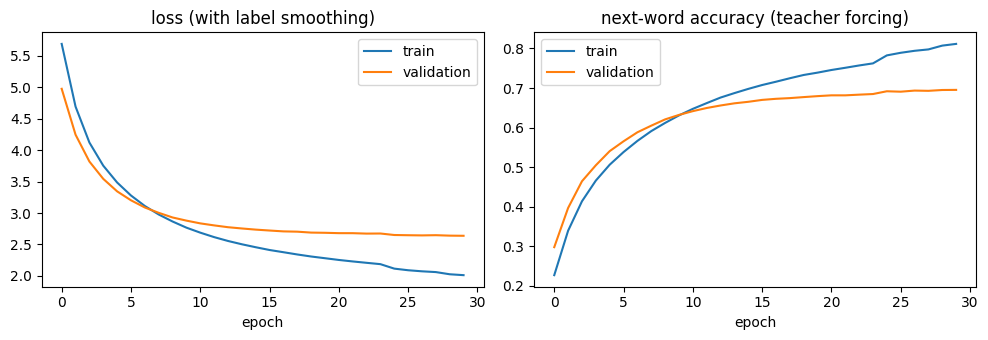

In [10]:
h = history.history
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="validation")
ax[0].set_title("loss (with label smoothing)"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(h["masked_acc"], label="train"); ax[1].plot(h["val_masked_acc"], label="validation")
ax[1].set_title("next-word accuracy (teacher forcing)"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"results/{NAME}_curves.png", dpi=150); plt.show()

## 5. Decoding: greedy and batched beam search
Both use the **average probability of all the models** (with `N_MODELS = 1`, just the one model).

The beam search runs 64 sentences at a time (k × 64 rows per call), so all 5,000 test sentences take a few
minutes. A finished beam (it wrote `[end]`) keeps its score. The final choice uses the **length penalty**
of Google's GNMT (Wu et al., 2016): score / ((5 + length) / 6)^α. With α = 0 there is no
normalisation; α = 1 is close to dividing by the length (Notebook 5).

In [11]:
def to_words(ids):
    words = []
    for t in ids:
        if t == END or t == 0:
            break
        words.append(tgt_words[t])
    return " ".join(words)

def next_logp(src, dec, i):
    """log P(next word) at position i, averaged over the ensemble."""
    p = 0
    for m in models:
        p = p + tf.nn.softmax(m([src, dec], training=False)[:, i, :]).numpy()
    return np.log(p / len(models) + 1e-12)

def translate(sentences, chunk=512):
    """Greedy decoding."""
    out = []
    for k in range(0, len(sentences), chunk):
        src = src_vec([prepare_source(s) for s in sentences[k:k + chunk]]).numpy()
        dec = np.zeros((len(src), TGT_LEN - 1), dtype="int64"); dec[:, 0] = START
        for i in range(TGT_LEN - 2):
            dec[:, i + 1] = np.argmax(next_logp(src, dec, i), axis=-1)
        out += [to_words(row[1:]) for row in dec]
    return out

def beam_translate(sentences, k=BEAM_K, alpha=ALPHA, chunk=64):
    """Batched beam search with the GNMT length penalty."""
    out = []
    for c in range(0, len(sentences), chunk):
        src = src_vec([prepare_source(s) for s in sentences[c:c + chunk]]).numpy()
        n, T = len(src), TGT_LEN - 1
        src_k = np.repeat(src, k, axis=0)                           # (n*k, 12)
        dec = np.zeros((n, k, T), dtype="int64"); dec[:, :, 0] = START
        scores = np.full((n, k), -1e9); scores[:, 0] = 0.0          # one live beam at the start
        done = np.zeros((n, k), dtype=bool)
        for i in range(T - 1):
            logp = next_logp(src_k, dec.reshape(n * k, T), i).reshape(n, k, -1)
            V = logp.shape[-1]
            logp[done] = -1e9; logp[done, 0] = 0.0                   # a finished beam only "writes" padding
            cand = (scores[:, :, None] + logp).reshape(n, -1)      # (n, k*V)
            top = np.argpartition(-cand, k, axis=1)[:, :k]
            beam, tok = top // V, top % V
            rows = np.arange(n)[:, None]
            dec = dec[rows, beam]; done = done[rows, beam]
            dec[:, :, i + 1] = np.where(done, 0, tok)
            scores = cand[rows, top]
            done = done | (tok == END)
            if done.all():
                break
        length = (dec[:, :, 1:] != 0).sum(-1)                       # words + [end]
        final = scores / ((5.0 + length) / 6.0) ** alpha
        best = final.argmax(axis=1)
        out += [to_words(dec[j, best[j], 1:]) for j in range(n)]
    return out

for s in ["i am hungry", "i have never seen such a beautiful city"]:
    print(s, "->", translate([s])[0], "| beam:", beam_translate([s])[0])

i am hungry -> tengo hambre | beam: tengo hambre
i have never seen such a beautiful city -> nunca he visto una ciudad tan bella | beam: nunca he visto una ciudad tan bella


## 6. Evaluate: BLEU on all 5,000 test sentences

In [12]:
def bleu(references, hypotheses, max_n=4):
    """Corpus BLEU (Papineni et al., 2002), 0-100, with one reference per sentence.
    Geometric mean of the 1- to 4-gram precisions, times a brevity penalty."""
    matches, totals = [0] * max_n, [0] * max_n
    ref_len = hyp_len = 0
    for ref, hyp in zip(references, hypotheses):
        ref, hyp = ref.split(), hyp.split()
        ref_len += len(ref); hyp_len += len(hyp)
        for n in range(1, max_n + 1):
            ref_ngrams = collections.Counter(tuple(ref[i:i + n]) for i in range(len(ref) - n + 1))
            hyp_ngrams = collections.Counter(tuple(hyp[i:i + n]) for i in range(len(hyp) - n + 1))
            matches[n - 1] += sum(min(c, ref_ngrams[g]) for g, c in hyp_ngrams.items())  # clipped counts
            totals[n - 1] += max(len(hyp) - n + 1, 0)
    # precision of each n-gram order; "+1" smoothing for n > 1 so that one order without matches
    # (e.g. no 4-grams in a 3-word sentence) does not make the whole score 0
    precisions = [matches[0] / max(totals[0], 1)] +                  [(m + 1) / (t + 1) for m, t in zip(matches[1:], totals[1:])]
    if precisions[0] == 0:
        return 0.0
    log_precision = sum(math.log(p) for p in precisions) / max_n
    brevity = min(1.0, math.exp(1 - ref_len / max(hyp_len, 1)))         # penalise short translations
    return 100 * brevity * math.exp(log_precision)

print("identical  :", round(bleu(["yo tengo hambre"], ["yo tengo hambre"]), 1))
print("one word   :", round(bleu(["el gato está en la mesa"], ["el perro está en la mesa"]), 1))

identical  : 100.0
one word   : 63.9


In [13]:
N_TEST = 300 if QUICK else len(test)
refs = list(test.es[:N_TEST]); english = list(test.en[:N_TEST])
t0 = time.time(); greedy = translate(english); t_greedy = time.time() - t0
t0 = time.time(); beam = beam_translate(english); t_beam = time.time() - t0
greedy_bleu, beam_bleu = bleu(refs, greedy), bleu(refs, beam)
exact = np.mean([r == h for r, h in zip(refs, beam)]) * 100
print(f"greedy: BLEU {greedy_bleu:.1f} ({t_greedy:.0f} s) | beam k={BEAM_K}: BLEU {beam_bleu:.1f} "
      f"({t_beam:.0f} s) | exact (beam) {exact:.1f}%")

lengths = np.array([len(s.split()) for s in english])
by_length = {}
for lo, hi in [(1, 3), (4, 5), (6, 7), (8, 10)]:
    idx = np.where((lengths >= lo) & (lengths <= hi))[0]
    by_length[f"{lo}-{hi}"] = round(bleu([refs[i] for i in idx], [beam[i] for i in idx]), 1)
print("BLEU by English length (beam):", by_length)

greedy: BLEU 35.2 (8 s) | beam k=8: BLEU 36.7 (112 s) | exact (beam) 17.8%
BLEU by English length (beam): {'1-3': 35.8, '4-5': 41.4, '6-7': 38.9, '8-10': 30.5}


In [14]:
EXAMPLES = ["i am hungry", "where is the train station", "the cat is sleeping on the sofa",
            "she does not like coffee", "we will go to the beach tomorrow",
            "my brother has two children", "can you help me please",
            "i have never seen such a beautiful city"]
some = test.sample(8, random_state=3)
sentences = EXAMPLES + list(some.en)
table = pd.DataFrame({"English": sentences, "greedy": translate(sentences),
                      "beam": beam_translate(sentences),
                      "reference": [""] * len(EXAMPLES) + list(some.es)})
table.to_csv(f"results/{NAME}_examples.csv", index=False)
pd.set_option("display.max_colwidth", 60)
table

,English,greedy,beam,reference
0,i am hungry,tengo hambre,tengo hambre,
1,where is the train station,dónde está la estación de tren,dónde está la estación de tren,
2,the cat is sleeping on the sofa,el gato está durmiendo en el sofá,el gato está durmiendo en el sofá,
3,she does not like coffee,a ella no le gusta el café,a ella no le gusta el café,
4,we will go to the beach tomorrow,vamos a ir a la playa mañana,nosotros vamos a la playa mañana,
5,my brother has two children,mi hermano tiene dos hijos,mi hermano tiene dos hijos,
6,can you help me please,puedes ayudarme por favor,puedes ayudarme por favor,
7,i have never seen such a beautiful city,nunca he visto una ciudad tan bella,nunca he visto una ciudad tan bella,
8,i wash my face every morning,me lavo la garganta todos los domingos,me rompí las manos todas las mañanas,me lavo la cara cada mañana
9,why dont you wait outside,por qué no esperás afuera,por qué no esperás afuera,por qué no esperás afuera


In [15]:
results = {"name": NAME, "model": MODEL_LABEL, "params": int(models[0].count_params()),
           "n_models": N_MODELS, "train_pairs": len(train),
           "epochs": epochs_run, "minutes": round(minutes, 1),
           "s_per_epoch": round(60 * minutes / sum(len(h.history["loss"]) for h in histories)),
           "val_acc": round(100 * max(history.history["val_masked_acc"]), 1),
           "bleu": round(beam_bleu, 1), "greedy_bleu": round(greedy_bleu, 1), "exact": round(exact, 1),
           "bleu_by_length": by_length,
           "examples": dict(zip(EXAMPLES, table.beam[:len(EXAMPLES)]))}
json.dump(results, open(f"results/{NAME}_results.json", "w"), indent=2, ensure_ascii=False)
print(json.dumps(results, indent=2, ensure_ascii=False))
print(f">>> params = {results['params']:,} x {N_MODELS} | train pairs = {len(train):,} | "
      f"greedy BLEU = {results['greedy_bleu']} | beam BLEU = {results['bleu']} | "
      f"training time = {results['minutes']} min")

{
  "name": "nb6",
  "model": "Sutskever tuned",
  "params": 17598224,
  "n_models": 1,
  "train_pairs": 94952,
  "epochs": 30,
  "minutes": 26.3,
  "s_per_epoch": 53,
  "val_acc": 69.5,
  "bleu": 36.7,
  "greedy_bleu": 35.2,
  "exact": 17.8,
  "bleu_by_length": {
    "1-3": 35.8,
    "4-5": 41.4,
    "6-7": 38.9,
    "8-10": 30.5
  },
  "examples": {
    "i am hungry": "tengo hambre",
    "where is the train station": "dónde está la estación de tren",
    "the cat is sleeping on the sofa": "el gato está durmiendo en el sofá",
    "she does not like coffee": "a ella no le gusta el café",
    "we will go to the beach tomorrow": "nosotros vamos a la playa mañana",
    "my brother has two children": "mi hermano tiene dos hijos",
    "can you help me please": "puedes ayudarme por favor",
    "i have never seen such a beautiful city": "nunca he visto una ciudad tan bella"
  }
}
>>> params = 17,598,224 x 1 | train pairs = 94,952 | greedy BLEU = 35.2 | beam BLEU = 36.7 | training time = 26.3 

## 7. The ladder, NB1 to NB6
Reads `results/nb*_results.json` (copy the files of the other notebooks here).

,notebook,model,weights,minutes,BLEU
0,NB1,aligned LSTM,"11,668,120",6.4,12.1
1,NB2,encoder-decoder GRU,"16,298,648",6.3,22.9
2,NB3,encoder-decoder LSTM,"17,083,032",8.0,20.5
3,NB4,bidirectional LSTM encoder,"16,558,744",9.6,23.4
4,NB5,"Sutskever: 2-layer LSTM, reversed source","21,281,432",19.2,20.5
5,NB6,Sutskever tuned,"17,598,224",26.3,36.7


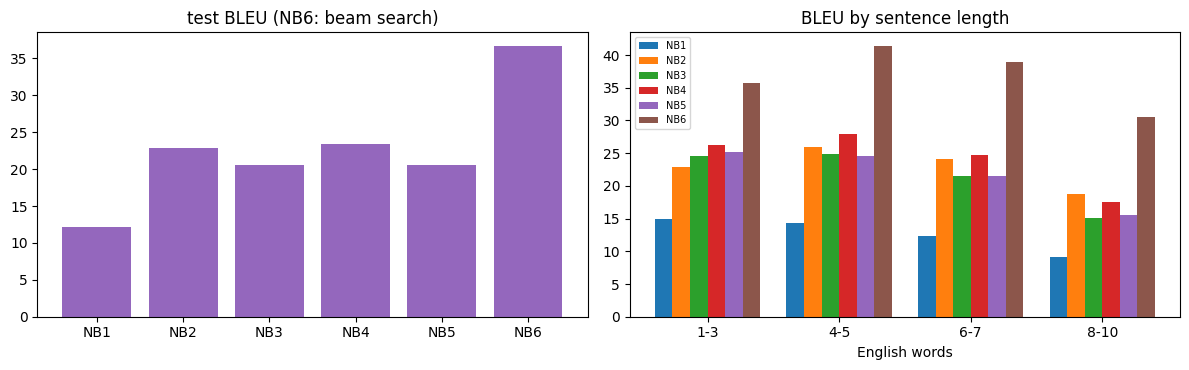

In [16]:
rows, by_len = [], {}
for n in range(1, 7):
    f = f"results/nb{n}_results.json"
    if os.path.exists(f):
        r = json.load(open(f))
        rows.append({"notebook": f"NB{n}", "model": r["model"], "weights": f"{r['params']:,}",
                     "minutes": r["minutes"], "BLEU": r["bleu"]})
        by_len[f"NB{n}"] = r["bleu_by_length"]
display(pd.DataFrame(rows))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar([r["notebook"] for r in rows], [r["BLEU"] for r in rows], color="tab:purple")
ax[0].set_title("test BLEU (NB6: beam search)")
buckets = ["1-3", "4-5", "6-7", "8-10"]
w = 0.8 / max(len(by_len), 1)
for j, (lab, d) in enumerate(by_len.items()):
    ax[1].bar(np.arange(4) + j * w, [d[b] for b in buckets], w, label=lab)
ax[1].set_xticks(np.arange(4) + 0.4 - w / 2, buckets); ax[1].set_xlabel("English words")
ax[1].set_title("BLEU by sentence length"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig("results/nb6_ladder.png", dpi=150); plt.show()

## Questions and experiments
1. Where does NB6 land on the ladder? Compare greedy NB6 with greedy NB5 (20.5) and beam NB6 with beam NB5.
2. **Ablation**: switch one tweak back to its Notebook 5 value at a time (`USE_ALL_PAIRS = False`,
   `TIE_WEIGHTS = False`, `LABEL_SMOOTHING = 0`, ...). Which one matters most?
3. `ALPHA = 0` vs `ALPHA = 1`: what happens to the length of the translations?
4. `N_MODELS = 3`: is the ensemble worth three times the training time?
5. Look at BLEU by length: did any tweak fix the long sentences? Why not? (Session 11: attention.)